In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

crime = pd.read_excel("Toronto_Crime_Dashboard_Data.xlsx", sheet_name="Neighbourhood_Crime")
print(crime.shape)
crime.head()

(17064, 8)


,UIN,HOOD_ID,AREA_NAME,YEAR,CRIME_TYPE,CRIME_COUNT,CRIME_RATE_PER_100K,POPULATION
0,001_2014,1,West Humber-Clairville,2014,Assault,289,839.21,34437
1,001_2014,1,West Humber-Clairville,2014,Auto Theft,311,903.10,34437
2,001_2014,1,West Humber-Clairville,2014,Bicycle Theft,4,11.62,34437
3,001_2014,1,West Humber-Clairville,2014,Break and Enter,148,429.77,34437
4,001_2014,1,West Humber-Clairville,2014,Homicide,0,0.00,34437


In [3]:
violent_types = ["Assault", "Robbery", "Shooting & Firearm Discharge", "Homicide"]
property_types = ["Break and Enter", "Auto Theft", "Theft from Motor Vehicle", "Theft Over $5000", "Bicycle Theft"]

print(crime["CRIME_TYPE"].unique())

['Assault' 'Auto Theft' 'Bicycle Theft' 'Break and Enter' 'Homicide'
 'Robbery' 'Shooting & Firearm Discharge' 'Theft Over $5000'
 'Theft from Motor Vehicle']


In [4]:
population = crime.drop_duplicates(["HOOD_ID", "YEAR"])[["HOOD_ID", "AREA_NAME", "YEAR", "POPULATION"]]

person_years_all = population.groupby(["HOOD_ID", "AREA_NAME"])["POPULATION"].sum()                                 # 2014-2025
person_years_recent = population[population["YEAR"] >= 2023].groupby(["HOOD_ID", "AREA_NAME"])["POPULATION"].sum()  # 2023-2025
person_years_early = population[population["YEAR"] <= 2016].groupby(["HOOD_ID", "AREA_NAME"])["POPULATION"].sum()   # 2014-2016

print(len(person_years_all), "neighbourhoods")

158 neighbourhoods


In [5]:
all_counts = crime.groupby(["HOOD_ID", "AREA_NAME"])["CRIME_COUNT"].sum()
violent_counts = crime[crime["CRIME_TYPE"].isin(violent_types)].groupby(["HOOD_ID", "AREA_NAME"])["CRIME_COUNT"].sum()
property_counts = crime[crime["CRIME_TYPE"].isin(property_types)].groupby(["HOOD_ID", "AREA_NAME"])["CRIME_COUNT"].sum()
recent_counts = crime[crime["YEAR"] >= 2023].groupby(["HOOD_ID", "AREA_NAME"])["CRIME_COUNT"].sum()
early_counts = crime[crime["YEAR"] <= 2016].groupby(["HOOD_ID", "AREA_NAME"])["CRIME_COUNT"].sum()

scores = pd.DataFrame({
    "all_rate": all_counts / person_years_all * 100000,
    "violent_rate": violent_counts / person_years_all * 100000,
    "property_rate": property_counts / person_years_all * 100000,
    "recent_rate": recent_counts / person_years_recent * 100000,
    "early_rate": early_counts / person_years_early * 100000,
})
scores["trend"] = scores["recent_rate"] / scores["early_rate"] - 1
scores = scores.reset_index()

# Toronto as a whole, for comparison
city_all_rate = crime["CRIME_COUNT"].sum() / population["POPULATION"].sum() * 100000
city_recent_rate = crime[crime["YEAR"] >= 2023]["CRIME_COUNT"].sum() / population[population["YEAR"] >= 2023]["POPULATION"].sum() * 100000
city_early_rate = crime[crime["YEAR"] <= 2016]["CRIME_COUNT"].sum() / population[population["YEAR"] <= 2016]["POPULATION"].sum() * 100000
print("Toronto all crime per 100k a year:", round(city_all_rate))
print("Toronto trend, 2014-16 to 2023-25:", f"{city_recent_rate / city_early_rate - 1:+.1%}")

scores.head()

Toronto all crime per 100k a year: 1710
Toronto trend, 2014-16 to 2023-25: +10.7%


,HOOD_ID,AREA_NAME,all_rate,violent_rate,property_rate,recent_rate,early_rate,trend
0,1,West Humber-Clairville,3925.070658,1067.647272,2857.423386,4281.424818,3396.376551,0.260586
1,2,Mount Olive-Silverstone-Jamestown,1617.935351,995.180095,622.755256,1736.943907,1608.250255,0.080021
2,3,Thistletown-Beaumond Heights,1615.711999,726.250439,889.461559,1750.473514,1518.424396,0.152822
3,4,Rexdale-Kipling,1713.114132,804.920647,908.193485,1941.978912,1312.238250,0.479898
4,5,Elms-Old Rexdale,1618.073962,834.700661,783.373301,1949.292065,1309.775564,0.488264


In [6]:
n = len(scores)

scores["rank_all"] = scores["all_rate"].rank(method="min").astype(int)   # raw crime rank (1 = least crime)

scores["score_violent"] = 100 * (n - scores["violent_rate"].rank(method="min")) / (n - 1)
scores["score_property"] = 100 * (n - scores["property_rate"].rank(method="min")) / (n - 1)
scores["score_recent"] = 100 * (n - scores["recent_rate"].rank(method="min")) / (n - 1)
scores["score_trend"] = 100 * (n - scores["trend"].rank(method="min")) / (n - 1)

scores[["AREA_NAME", "rank_all", "score_violent", "score_property", "score_recent", "score_trend"]].sort_values("rank_all").head()

,AREA_NAME,rank_all,score_violent,score_property,score_recent,score_trend
104,Steeles,1,99.363057,98.089172,100.000000,62.420382
86,Yonge-St.Clair,2,96.815287,86.624204,96.815287,12.101911
136,Avondale,3,89.808917,95.541401,96.178344,2.547771
131,East L'Amoreaux,4,80.254777,98.726115,97.452229,43.312102
41,Pleasant View,5,92.993631,91.719745,95.541401,22.929936


In [7]:
w_violent = 0.35
w_property = 0.25
w_recent = 0.20
w_trend = 0.20

scores["pts_violent"] = w_violent * scores["score_violent"]
scores["pts_property"] = w_property * scores["score_property"]
scores["pts_recent"] = w_recent * scores["score_recent"]
scores["pts_trend"] = w_trend * scores["score_trend"]
scores["safety_score"] = scores["pts_violent"] + scores["pts_property"] + scores["pts_recent"] + scores["pts_trend"]
scores["rank_safety"] = scores["safety_score"].rank(ascending=False, method="min").astype(int)

top10 = scores.sort_values("rank_safety").head(10)
top10[["rank_safety", "AREA_NAME", "safety_score", "rank_all", "all_rate", "violent_rate", "trend"]].round(3)

,rank_safety,AREA_NAME,safety_score,rank_all,all_rate,violent_rate,trend
104,1,Steeles,91.783,1,655.472,213.943,0.073
102,2,Lambton Baby Point,89.331,10,919.337,422.398,-0.134
123,3,Guildwood,83.217,18,1029.413,477.163,-0.145
117,4,Centennial Scarborough,83.025,8,891.408,356.563,0.137
157,5,South Eglinton-Davisville,81.497,9,909.419,416.102,0.181
131,6,East L'Amoreaux,80.924,4,849.809,432.894,0.174
31,7,Westminster-Branson,79.968,16,1002.643,421.497,0.095
41,8,Pleasant View,79.172,5,861.607,334.644,0.300
7,9,Humber Heights-Westmount,78.535,39,1125.402,438.537,-0.131
94,10,Humewood-Cedarvale,78.057,48,1205.685,355.065,-0.169


In [8]:
equal_weights = 0.25 * scores["score_violent"] + 0.25 * scores["score_property"] + 0.25 * scores["score_recent"] + 0.25 * scores["score_trend"]
alt_40_30_15_15 = 0.40 * scores["score_violent"] + 0.30 * scores["score_property"] + 0.15 * scores["score_recent"] + 0.15 * scores["score_trend"]
alt_30_30_20_20 = 0.30 * scores["score_violent"] + 0.30 * scores["score_property"] + 0.20 * scores["score_recent"] + 0.20 * scores["score_trend"]
alt_40_20_20_20 = 0.40 * scores["score_violent"] + 0.20 * scores["score_property"] + 0.20 * scores["score_recent"] + 0.20 * scores["score_trend"]
alt_35_25_25_15 = 0.35 * scores["score_violent"] + 0.25 * scores["score_property"] + 0.25 * scores["score_recent"] + 0.15 * scores["score_trend"]

print("Main 35/25/20/20 :", scores.nlargest(3, "safety_score")["AREA_NAME"].tolist())
print("Equal 25 each    :", scores.loc[equal_weights.nlargest(3).index, "AREA_NAME"].tolist())
print("40/30/15/15      :", scores.loc[alt_40_30_15_15.nlargest(3).index, "AREA_NAME"].tolist())
print("30/30/20/20      :", scores.loc[alt_30_30_20_20.nlargest(3).index, "AREA_NAME"].tolist())
print("40/20/20/20      :", scores.loc[alt_40_20_20_20.nlargest(3).index, "AREA_NAME"].tolist())
print("35/25/25/15      :", scores.loc[alt_35_25_25_15.nlargest(3).index, "AREA_NAME"].tolist())

Main 35/25/20/20 : ['Steeles', 'Lambton Baby Point', 'Guildwood']
Equal 25 each    : ['Lambton Baby Point', 'Steeles', 'Guildwood']
40/30/15/15      : ['Steeles', 'Lambton Baby Point', 'Centennial Scarborough']
30/30/20/20      : ['Steeles', 'Lambton Baby Point', 'Guildwood']
40/20/20/20      : ['Steeles', 'Lambton Baby Point', 'Centennial Scarborough']
35/25/25/15      : ['Steeles', 'Lambton Baby Point', 'Centennial Scarborough']


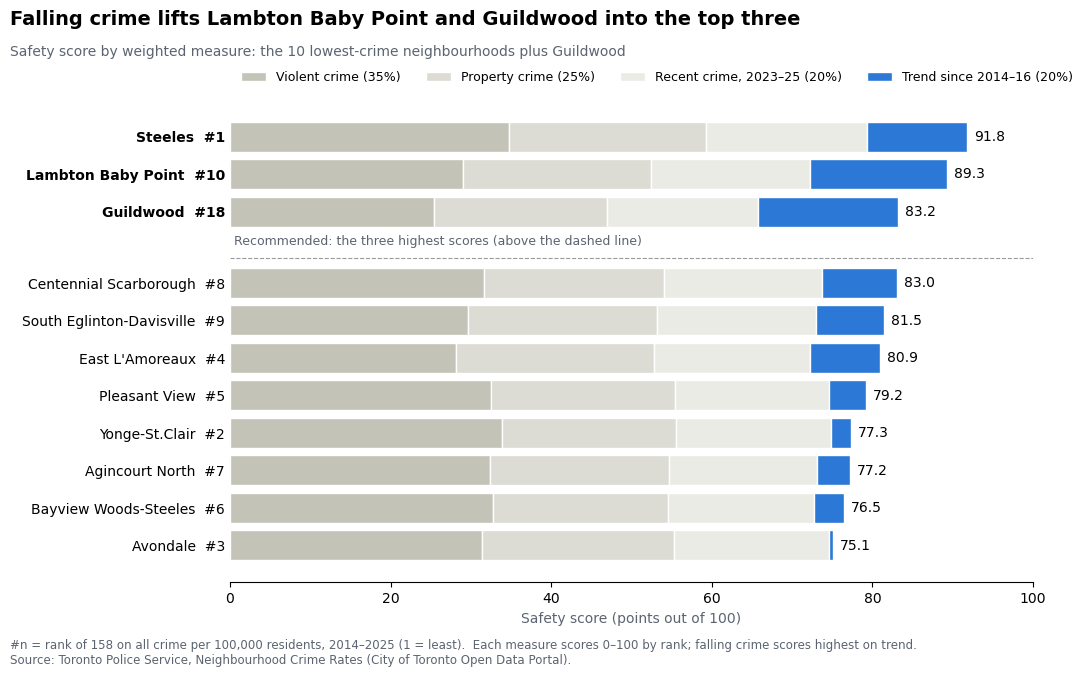

In [9]:
chart = scores[(scores["rank_all"] <= 10) | (scores["AREA_NAME"] == "Guildwood")]
chart = chart.sort_values("safety_score")   # barh draws the first row at the bottom, so the best ends up on top

labels = chart["AREA_NAME"] + "  #" + chart["rank_all"].astype(str)

# y positions: one row each, with an extra gap above the 8 lower rows to set the top three apart
y = np.arange(len(chart))
y = np.where(y >= len(chart) - 3, y + 0.9, y)

fig, ax = plt.subplots(figsize=(11, 6.8))
fig.subplots_adjust(left=0.22, right=0.95, top=0.85, bottom=0.14)

ax.barh(y, chart["pts_violent"], color="#c3c3b7", edgecolor="white", label="Violent crime (35%)")
ax.barh(y, chart["pts_property"], left=chart["pts_violent"],
        color="#dcdcd4", edgecolor="white", label="Property crime (25%)")
ax.barh(y, chart["pts_recent"], left=chart["pts_violent"] + chart["pts_property"],
        color="#ebebe6", edgecolor="white", label="Recent crime, 2023–25 (20%)")
trend_bars = ax.barh(y, chart["pts_trend"], left=chart["pts_violent"] + chart["pts_property"] + chart["pts_recent"],
                     color="#2b78d6", edgecolor="white", label="Trend since 2014–16 (20%)")

ax.bar_label(trend_bars, labels=chart["safety_score"].map("{:.1f}".format), padding=5, fontsize=10)

ax.set_yticks(y, labels)
# the three picks are the top three rows: bold names, a dashed divider and a note in the gap
tick_labels = ax.get_yticklabels()
tick_labels[-1].set_fontweight("bold")
tick_labels[-2].set_fontweight("bold")
tick_labels[-3].set_fontweight("bold")
ax.axhline(len(chart) - 3 - 0.35, color="#9a9a9a", linewidth=0.8, linestyle="--")
ax.text(0.5, len(chart) - 3 + 0.12, "Recommended: the three highest scores (above the dashed line)",
        ha="left", va="center", fontsize=9, color="#5b6470")

ax.set_xlim(0, 100)
ax.set_xlabel("Safety score (points out of 100)", color="#5b6470")
ax.tick_params(axis="y", length=0)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=4, frameon=False, fontsize=9)

fig.text(0.02, 0.96, "Falling crime lifts Lambton Baby Point and Guildwood into the top three",
         ha="left", fontsize=14, fontweight="bold")
fig.text(0.02, 0.915, "Safety score by weighted measure: the 10 lowest-crime neighbourhoods plus Guildwood",
         ha="left", fontsize=10, color="#5b6470")
fig.text(0.02, 0.02, "#n = rank of 158 on all crime per 100,000 residents, 2014–2025 (1 = least).  "
         "Each measure scores 0–100 by rank; falling crime scores highest on trend.\n"
         "Source: Toronto Police Service, Neighbourhood Crime Rates (City of Toronto Open Data Portal).",
         ha="left", fontsize=8.5, color="#5b6470")

fig.savefig("figure2_safety_score.png", dpi=200, bbox_inches="tight")
plt.show()